<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 3: Probability Distributions and Bayes’ Theorem

This notebook covers:
1. Generating and plotting samples from standard distributions (Bernoulli, Binomial, Poisson, Uniform, and Gaussian) alongside their theoretical PDFs/PMFs.
2. Computing the theoretical posterior probability $P(\text{Disease} \mid \text{Positive})$ using Bayes' theorem.
3. Simulating $100,000$ patients to verify the theoretical result empirically.
4. Plotting how the posterior probability changes as the disease prevalence varies from $0.1\%$ to $20\%$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Set random seed for reproducibility
np.random.seed(42)

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig_size = (15, 10)

## Task 1: Generate and Plot Probability Distributions

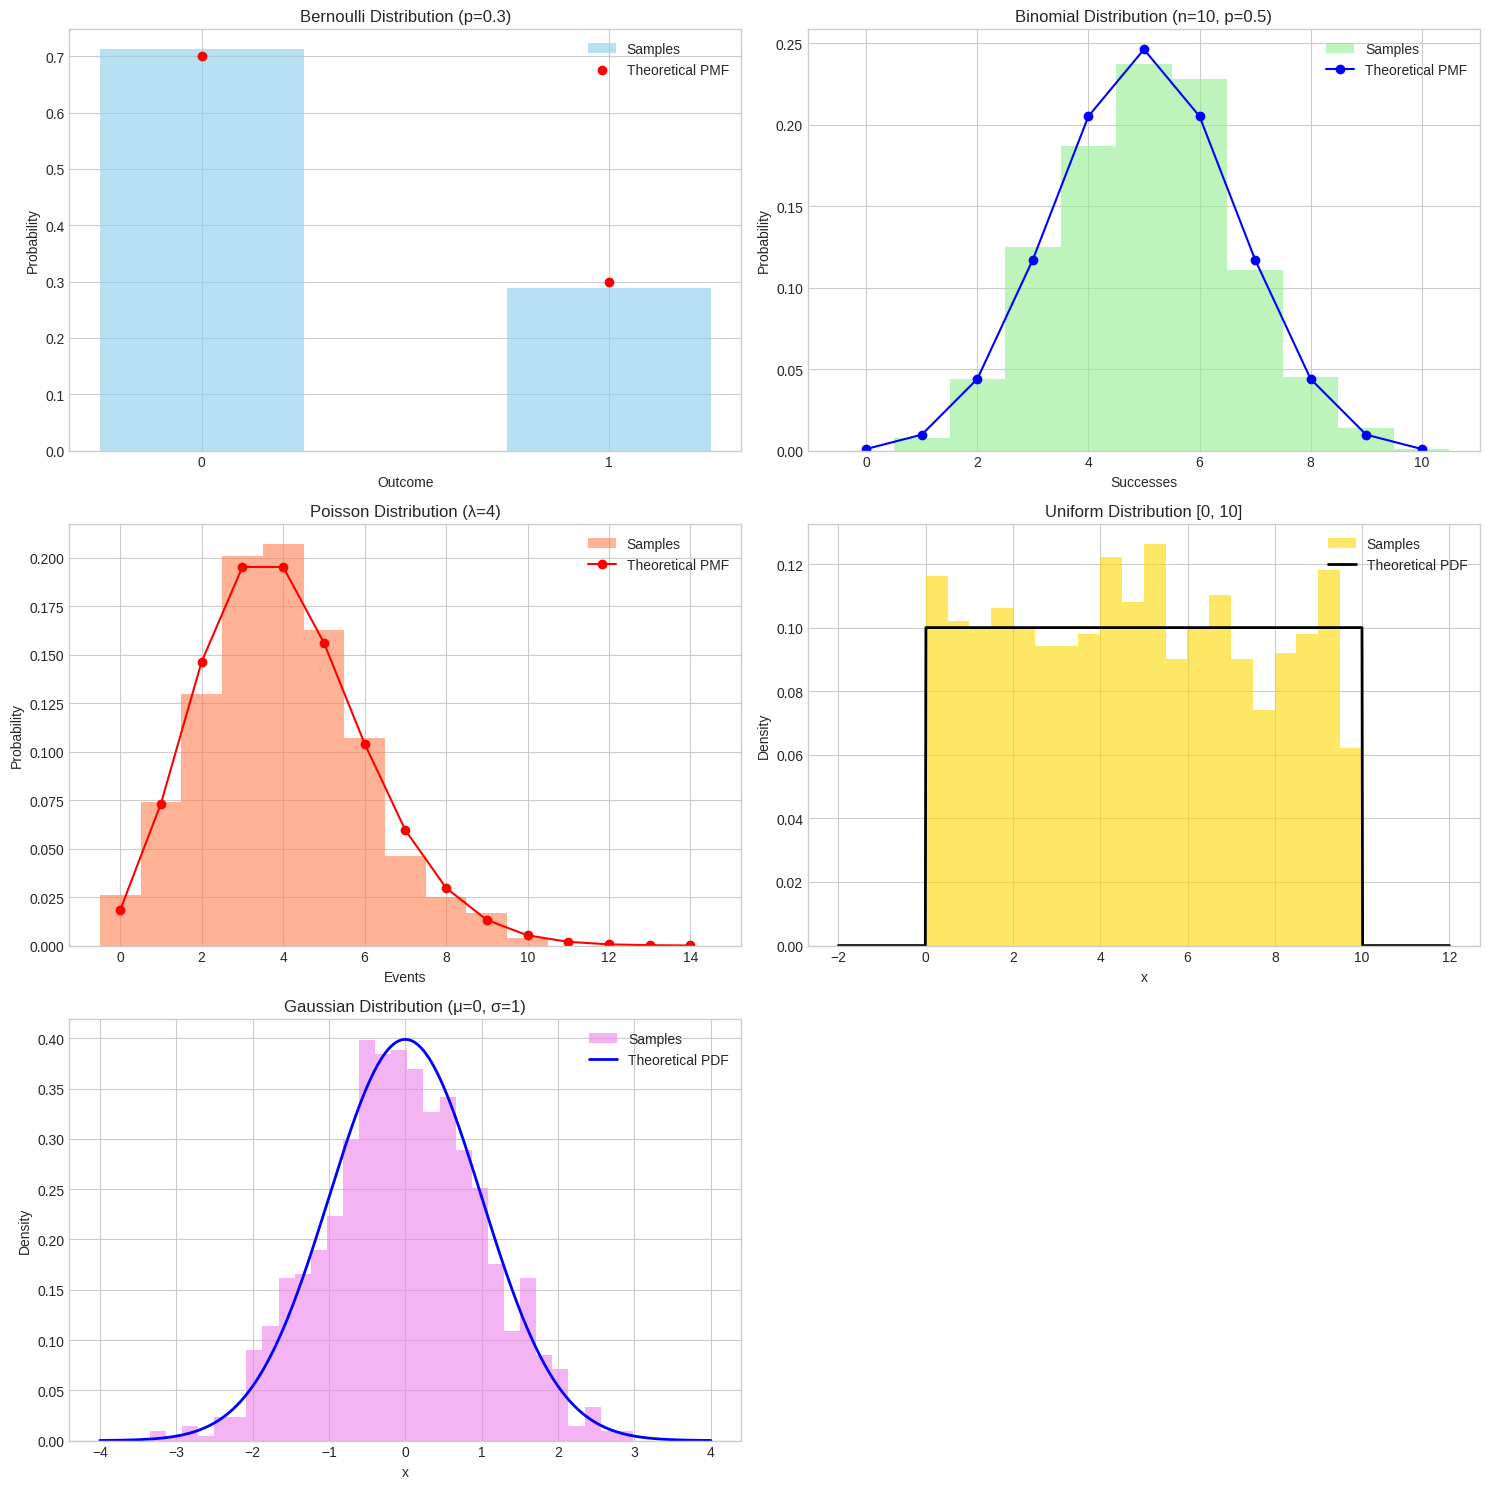

In [2]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

# 1. Bernoulli Distribution
p_bernoulli = 0.3
bernoulli_dist = stats.bernoulli(p_bernoulli)
bernoulli_samples = bernoulli_dist.rvs(size=1000)

axes[0].hist(bernoulli_samples, bins=[-0.5, 0.5, 1.5], rwidth=0.5, density=True, alpha=0.6, color='skyblue', label='Samples')
axes[0].scatter([0, 1], [bernoulli_dist.pmf(0), bernoulli_dist.pmf(1)], color='red', zorder=3, label='Theoretical PMF')
axes[0].set_xticks([0, 1])
axes[0].set_title(f'Bernoulli Distribution (p={p_bernoulli})')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Probability')
axes[0].legend()

# 2. Binomial Distribution
n_binom, p_binom = 10, 0.5
binom_dist = stats.binom(n_binom, p_binom)
binom_samples = binom_dist.rvs(size=1000)
x_binom = np.arange(0, n_binom + 1)

axes[1].hist(binom_samples, bins=np.arange(-0.5, n_binom + 1.5, 1), density=True, alpha=0.6, color='lightgreen', label='Samples')
axes[1].plot(x_binom, binom_dist.pmf(x_binom), 'bo-', label='Theoretical PMF')
axes[1].set_title(f'Binomial Distribution (n={n_binom}, p={p_binom})')
axes[1].set_xlabel('Successes')
axes[1].set_ylabel('Probability')
axes[1].legend()

# 3. Poisson Distribution
lam_poisson = 4
poisson_dist = stats.poisson(lam_poisson)
poisson_samples = poisson_dist.rvs(size=1000)
x_poisson = np.arange(0, 15)

axes[2].hist(poisson_samples, bins=np.arange(-0.5, 15.5, 1), density=True, alpha=0.6, color='coral', label='Samples')
axes[2].plot(x_poisson, poisson_dist.pmf(x_poisson), 'ro-', label='Theoretical PMF')
axes[2].set_title(f'Poisson Distribution (λ={lam_poisson})')
axes[2].set_xlabel('Events')
axes[2].set_ylabel('Probability')
axes[2].legend()

# 4. Uniform Distribution
low_unif, high_unif = 0, 10
uniform_dist = stats.uniform(loc=low_unif, scale=high_unif - low_unif)
uniform_samples = uniform_dist.rvs(size=1000)
x_unif = np.linspace(low_unif - 2, high_unif + 2, 1000)

axes[3].hist(uniform_samples, bins=20, density=True, alpha=0.6, color='gold', label='Samples')
axes[3].plot(x_unif, uniform_dist.pdf(x_unif), 'k-', lw=2, label='Theoretical PDF')
axes[3].set_title(f'Uniform Distribution [{low_unif}, {high_unif}]')
axes[3].set_xlabel('x')
axes[3].set_ylabel('Density')
axes[3].legend()

# 5. Gaussian (Normal) Distribution
mu_norm, sigma_norm = 0, 1
normal_dist = stats.norm(loc=mu_norm, scale=sigma_norm)
normal_samples = normal_dist.rvs(size=1000)
x_norm = np.linspace(mu_norm - 4*sigma_norm, mu_norm + 4*sigma_norm, 1000)

axes[4].hist(normal_samples, bins=30, density=True, alpha=0.6, color='violet', label='Samples')
axes[4].plot(x_norm, normal_dist.pdf(x_norm), 'b-', lw=2, label='Theoretical PDF')
axes[4].set_title(f'Gaussian Distribution (μ={mu_norm}, σ={sigma_norm})')
axes[4].set_xlabel('x')
axes[4].set_ylabel('Density')
axes[4].legend()

# Hide unused subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

## Tasks 2 & 3: Compute Bayes' Theorem and Verify Empirically

In [3]:
# Given Parameter values
prevalence = 0.01  # P(Disease)
sensitivity = 0.95 # P(Positive | Disease)
specificity = 0.90 # P(Negative | No Disease)

# 1. Theoretical Calculation using Bayes' Theorem
# P(Positive) = P(Positive | Disease) * P(Disease) + P(Positive | No Disease) * P(No Disease)
p_pos_given_no_disease = 1 - specificity
p_no_disease = 1 - prevalence

p_positive = (sensitivity * prevalence) + (p_pos_given_no_disease * p_no_disease)
p_disease_given_positive = (sensitivity * prevalence) / p_positive

print("--- Theoretical Calculation ---")
print(f"P(Disease | Positive) = {p_disease_given_positive:.6f} ({p_disease_given_positive*100:.2f}%)")

--- Theoretical Calculation ---
P(Disease | Positive) = 0.087558 (8.76%)


In [4]:
# 2. Empirical Verification via Simulation (100,000 patients)
num_patients = 100000

# Determine who has the disease based on disease prevalence
has_disease = np.random.rand(num_patients) < prevalence

# Simulate test outcomes based on sensitivity and specificity
test_positive = np.zeros(num_patients, dtype=bool)

# For those who have the disease, test is positive with probability = sensitivity
test_positive[has_disease] = np.random.rand(has_disease.sum()) < sensitivity

# For those who do not have the disease, test is positive with probability = (1 - specificity)
test_positive[~has_disease] = np.random.rand((~has_disease).sum()) < (1 - specificity)

# Compute empirical posterior
empirical_positive_count = test_positive.sum()
empirical_true_positive_count = (has_disease & test_positive).sum()

empirical_p_disease_given_positive = empirical_true_positive_count / empirical_positive_count

print("--- Empirical Simulation (100,000 patients) ---")
print(f"Total testing positive: {empirical_positive_count}")
print(f"True positives (have disease and tested positive): {empirical_true_positive_count}")
print(f"Empirical P(Disease | Positive) = {empirical_p_disease_given_positive:.6f} ({empirical_p_disease_given_positive*100:.2f}%)")

--- Empirical Simulation (100,000 patients) ---
Total testing positive: 10932
True positives (have disease and tested positive): 964
Empirical P(Disease | Positive) = 0.088181 (8.82%)


## Task 4: Plot Posterior vs Prevalence (0.1% to 20%)

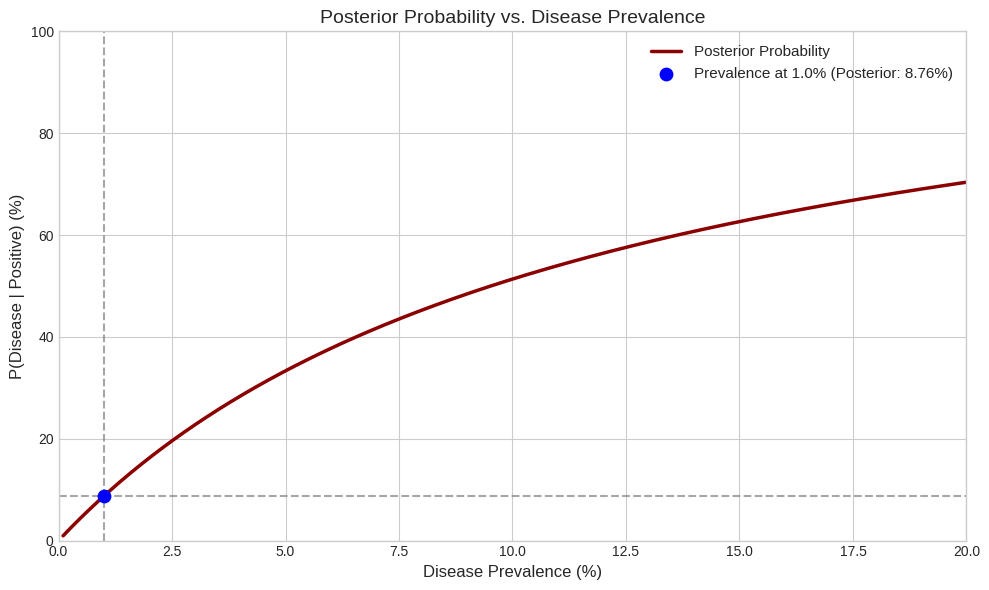

In [5]:
# Range of prevalence from 0.1% to 20%
prevalence_range = np.linspace(0.001, 0.20, 500)

# Calculate posterior probability for each prevalence value
posteriors = []
for p in prevalence_range:
    p_pos = (sensitivity * p) + ((1 - specificity) * (1 - p))
    post_p = (sensitivity * p) / p_pos
    posteriors.append(post_p)

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(prevalence_range * 100, np.array(posteriors) * 100, color='darkred', lw=2.5, label='Posterior Probability')

# Mark the current 1% prevalence reference point
plt.axvline(x=1.0, color='gray', linestyle='--', alpha=0.7)
plt.axhline(y=p_disease_given_positive * 100, color='gray', linestyle='--', alpha=0.7)
plt.scatter([1.0], [p_disease_given_positive * 100], color='blue', zorder=5, s=80,
            label=f'Prevalence at 1.0% (Posterior: {p_disease_given_positive*100:.2f}%)')

plt.title('Posterior Probability vs. Disease Prevalence', fontsize=14)
plt.xlabel('Disease Prevalence (%)', fontsize=12)
plt.ylabel('P(Disease | Positive) (%)', fontsize=12)
plt.xlim(0, 20)
plt.ylim(0, 100)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()